# KDD — Segmentação de produtos

Este notebook percorre as seis etapas do processo KDD (*Knowledge Discovery in Databases*) e chama as mesmas funções do pacote `kdd/` usadas por `python main.py`.

**Pergunta de negócio:** existem grupos naturais de produtos, segundo preço e volume de vendas, que permitam orientar precificação, promoções e estoque?

> Os dados são **sintéticos** (gerados por `kdd/gerar_dados.py`) e incluem de propósito os problemas comuns em bases reais.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
from IPython.display import Image

from kdd import avaliacao, gerar_dados, graficos, mineracao
from kdd.config import DADOS_BRUTOS, DIR_FIGURAS
from kdd.preprocessamento import preprocessar
from kdd.reducao import reduzir
from kdd.selecao import selecionar
from kdd.transformacao import transformar

pd.set_option("display.width", 140)

## 0. Dados brutos

In [2]:
if not DADOS_BRUTOS.exists():
    gerar_dados.salvar(gerar_dados.gerar())

brutos = pd.read_csv(DADOS_BRUTOS)
print(brutos.shape)
brutos.head()

(1246, 10)


,ID_Produto,Nome_Produto,Categoria,Preço,Vendas,Cor,Tamanho,Fornecedor,Codigo_Barras,Data_Cadastro
0,P00736,Saia modelo 736,Saia,56.32,100.0,branco,M,F12,1547621854264,2024-04-30
1,P00443,Vestido modelo 443,VESTIDO,186.24,110.0,verde,P,F11,3349054979223,2023-06-15
2,P01118,Vestido modelo 1118,vestido,"R$ 164,57",82.0,azul,P,F10,4756742426787,2024-04-13
3,P00334,Vestido modelo 334,Vestido,123.04,63.0,branco,PP,F10,8847908773514,2024-01-30
4,P00328,Calça modelo 328,calça,98.92,77.0,preto,M,F11,2840272795125,2024-03-18


In [3]:
# Problemas visíveis: grafias diferentes, preço como texto, ausentes
print(brutos["Categoria"].value_counts(dropna=False).head(12), "\n")
print(brutos["Preço"].astype(str).str.contains("R\\$").sum(), "preços no formato 'R$ 1.234,56'")
brutos.isna().sum()

Categoria
CAMISA       103
camisa        97
 camisa       88
Camisa        85
Vestido       79
CALÇA         76
vestido       65
Saia          63
saia          61
calça         60
SAIA          59
vestido       57
Name: count, dtype: int64 

121 preços no formato 'R$ 1.234,56'


ID_Produto        0
Nome_Produto      0
Categoria        13
Preço            51
Vendas           52
Cor               0
Tamanho           0
Fornecedor        0
Codigo_Barras     0
Data_Cadastro     0
dtype: int64

## 1. Seleção

Redução **vertical**: dos 10 atributos, mantemos os 4 relevantes para o problema (`ID_Produto`, `Categoria`, `Preço` e `Vendas`). Cor, tamanho, fornecedor, código de barras e data de cadastro não respondem à pergunta de negócio.

In [4]:
selecionado = selecionar(brutos)
selecionado.head()

,ID_Produto,Categoria,Preço,Vendas
0,P00736,Saia,56.32,100.0
1,P00443,VESTIDO,186.24,110.0
2,P01118,vestido,"R$ 164,57",82.0
3,P00334,Vestido,123.04,63.0
4,P00328,calça,98.92,77.0


## 2. Pré-processamento

1. **Normalização de texto**: espaços, maiúsculas e acentos (`" CALCA"` → `"calça"`).
2. **Conversão de tipos**: `"R$ 1.234,56"` → `1234.56`.
3. **Duplicatas**: removidas por `ID_Produto` *depois* de normalizar o texto, para que `"CAMISA"` e `"camisa"` sejam reconhecidas como o mesmo registro.
4. **Valores inválidos**: preço ≤ 0 ou vendas < 0 são removidos. Preços acima da cerca extrema de Tukey (Q3 + 3·IQR, em escala log) são tratados como erro de digitação.
5. **Ausentes**: preenchidos com a **mediana da categoria**, que é mais robusta que a média global.

In [5]:
limpo, rel_pre = preprocessar(selecionado)
rel_pre

{'registros_entrada': 1246,
 'duplicatas_removidas': 46,
 'invalidos_removidos': 9,
 'extremos_removidos': 3,
 'limite_preco_extremo': 1886.5,
 'sem_categoria_removidos': 12,
 'ausentes_preenchidos': {'Preço': 47, 'Vendas': 48},
 'registros_saida': 1176}

## 3. Transformação

- `Faixa_Preço`: discretização do preço em **tercis** (Baixo/Médio/Alto), com faixas do mesmo tamanho.
- `Receita = Preço × Vendas`.
- **log + Min-Max**: preço, vendas e receita são assimétricos à direita. Sem o log, poucos produtos caros dominariam as distâncias do K-Means. Depois do log, tudo é escalado para [0, 1].

In [6]:
transformado = transformar(limpo)
transformado.describe().round(2)

,Preço,Vendas,Receita,Preço_norm,Vendas_norm,Receita_norm
count,1176.00,1176.00,1176.00,1176.00,1176.00,1176.00
mean,111.41,124.46,10639.34,0.45,0.50,0.48
std,68.01,82.77,5225.35,0.20,0.18,0.15
min,26.66,16.00,2088.06,0.00,0.00,0.00
25%,60.50,61.00,6858.54,0.29,0.36,0.37
50%,88.38,98.00,9517.10,0.43,0.50,0.48
75%,144.62,170.25,13131.41,0.60,0.65,0.58
max,434.80,591.00,50063.16,1.00,1.00,1.00


## 4. Redução de dados

Filtros independentes de modelo: variância mínima e correlação máxima de 0,9.

O ANOVA F (`f_classif`) contra a `Categoria` aparece **apenas como diagnóstico**. Na versão original, ele escolhia o único atributo usado no agrupamento. Como o K-Means é não supervisionado, escolher atributos pelo rótulo faz os clusters apenas reproduzirem as categorias já conhecidas.

In [7]:
reduzido, atributos, rel_red = reduzir(transformado)
print("Selecionados:", atributos)
print("ANOVA F (diagnóstico):", rel_red["anova_f_vs_categoria"])
pd.DataFrame(rel_red["correlacao"])

Selecionados: ['Preço_norm', 'Vendas_norm', 'Receita_norm']
ANOVA F (diagnóstico): {'Preço_norm': 1185.5, 'Vendas_norm': 845.2, 'Receita_norm': 82.7}


,Preço_norm,Vendas_norm,Receita_norm
Preço_norm,1.000,-0.718,0.180
Vendas_norm,-0.718,1.000,0.556
Receita_norm,0.180,0.556,1.000


## 5. Mineração — K-Means

Em vez de fixar k = 3, testamos k de 2 a 8 e escolhemos o de **maior silhueta**. O gráfico do cotovelo aparece ao lado como apoio.

,k,inercia,silhueta
0,2,60.811,0.400
1,3,41.668,0.374
2,4,31.548,0.378
3,5,26.146,0.352
4,6,22.181,0.347
5,7,19.127,0.349
6,8,16.619,0.356


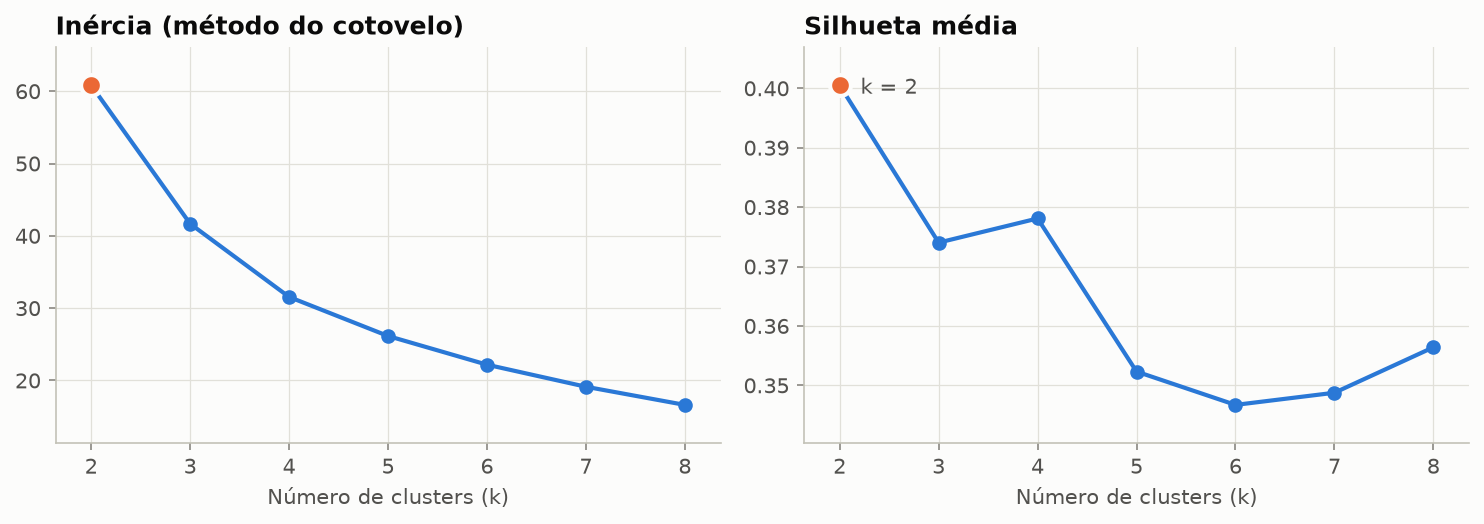

In [8]:
X = reduzido[atributos].to_numpy()
avaliacao_k = mineracao.avaliar_k(X)
k = mineracao.escolher_k(avaliacao_k)

graficos.escolha_k(avaliacao_k, k, DIR_FIGURAS / "escolha_k.png")
display(avaliacao_k.round(3))
Image(DIR_FIGURAS / "escolha_k.png")

In [9]:
rotulos, modelo = mineracao.agrupar(X, k, ordenar_por=reduzido["Preço"].to_numpy())
reduzido["Cluster"] = rotulos
reduzido["Cluster"].value_counts().sort_index()

Cluster
0    659
1    517
Name: count, dtype: int64

## 6. Avaliação e interpretação

Três métricas internas: **silhueta** (maior é melhor), **Davies-Bouldin** (menor é melhor) e **Calinski-Harabasz** (maior é melhor).

In [10]:
avaliacao.metricas(X, rotulos)

{'silhueta': 0.4, 'davies_bouldin': 0.965, 'calinski_harabasz': 1013.9}

,Produtos,Preço_mediano,Vendas_medianas,Receita_total,Categoria_predominante,Pct_predominante,Pct_receita,Segmento
Cluster,,,,,,,,
0,659,63.51,158.0,7558878.0,camisa,53.9,60.4,Preço baixo · giro alto
1,517,153.69,58.0,4952991.0,vestido,47.0,39.6,Preço alto · giro baixo


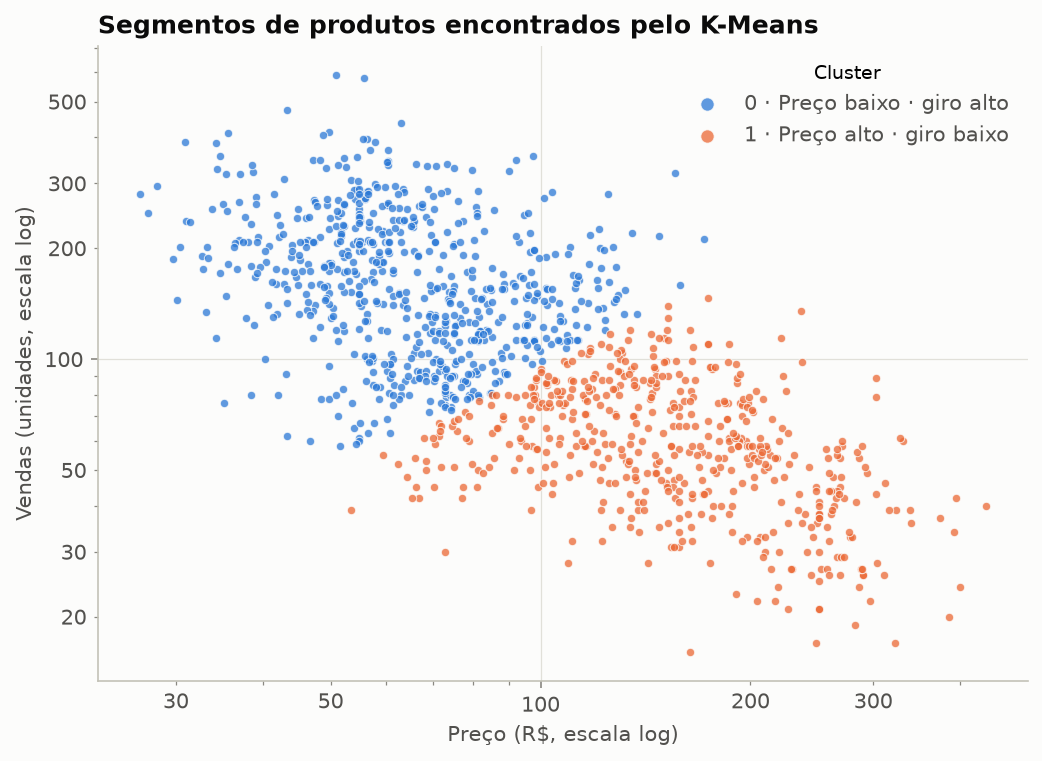

In [11]:
perfil = avaliacao.perfil(reduzido)
graficos.dispersao_clusters(reduzido, perfil, DIR_FIGURAS / "clusters.png")
display(perfil)
Image(DIR_FIGURAS / "clusters.png")

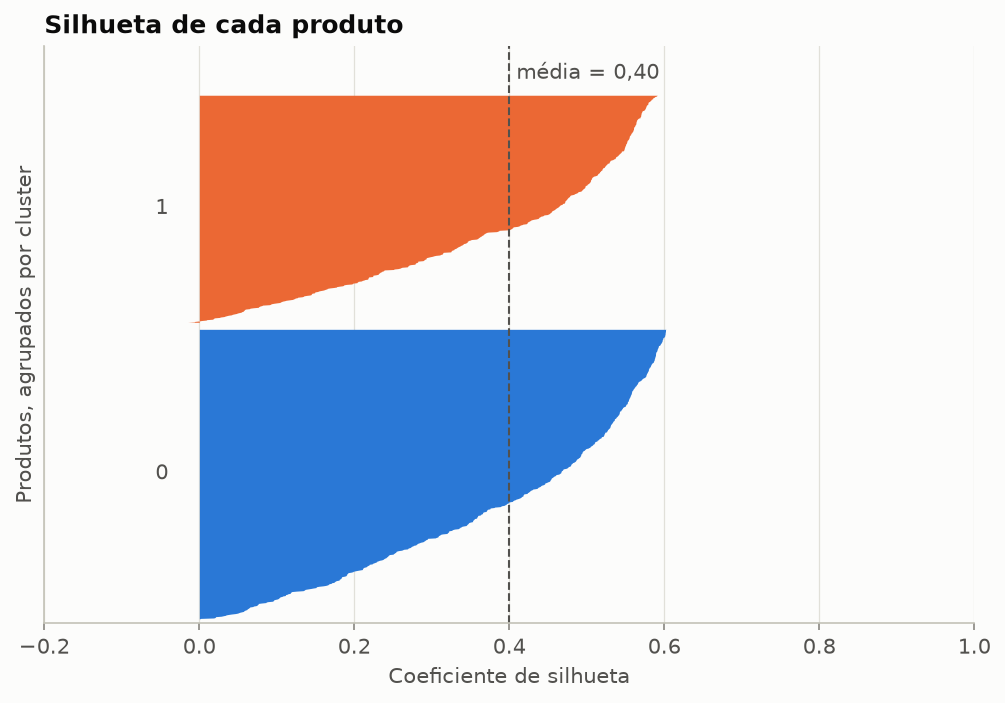

In [12]:
graficos.silhueta_por_amostra(X, rotulos, avaliacao.metricas(X, rotulos)["silhueta"], DIR_FIGURAS / "silhueta.png")
Image(DIR_FIGURAS / "silhueta.png")

A categoria **não** foi usada no agrupamento. Por isso, cruzar categoria com cluster funciona como validação externa: mostra se os segmentos encontrados fazem sentido para o negócio.

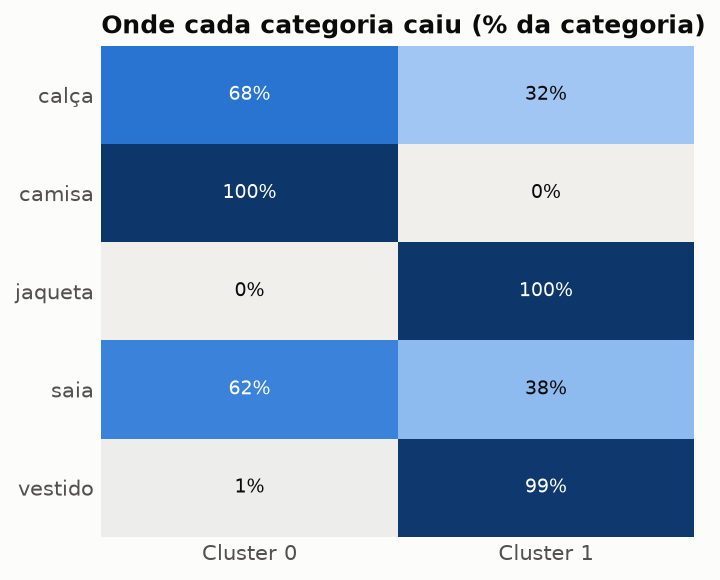

In [13]:
tabela = avaliacao.categoria_por_cluster(reduzido)
graficos.mapa_categoria_cluster(tabela, DIR_FIGURAS / "categoria_por_cluster.png")
Image(DIR_FIGURAS / "categoria_por_cluster.png")

## Conclusões

- A melhor partição tem **k = 2**: um segmento de **preço baixo e giro alto** (camisas, maioria das calças e saias) e outro de **preço alto e giro baixo** (vestidos e jaquetas).
- A silhueta de **≈ 0,40** indica estrutura moderada. Preço e vendas formam um contínuo, e não grupos totalmente isolados. Essa leitura é mais realista que o 0,80 da versão original, obtido com um único atributo e uma base pequena.
- **Calças e saias se dividem** entre os dois segmentos: parte delas se comporta como produto de entrada e parte como premium. Esses itens merecem análise individual de preço.
- O segmento de giro alto concentra cerca de 60% da receita e combina com estratégias de volume e reposição frequente. O segmento premium combina com margem e estoque mais enxuto.